In [1]:
import os
import time
import pickle
import numpy as np
import matplotlib.pyplot as plt

from dataclasses import dataclass
from typing import Optional, Tuple, Dict, Any


In [2]:
ROOT = "data"  # or your project root
NPZ_PATH = os.path.join(ROOT, "correlations_dl", "npairs_compact.npz")

INITIAL_NODE_BINS_PATH = os.path.join(ROOT, "nodes_labels_initial_fc_200_ext.npy")
NODE_INDICES_PHOTO_PATH = os.path.join(ROOT, "node_indices_fc.npy")

# user-specified reference labels path
REFERENCE_LABELS_PATH = os.path.join(ROOT, "reference_labels_fc_fc.npy")

# optional "true TreeCorr column" pickles
DD_PKL = os.path.join(ROOT, "correlations_dl", "dd.pkl")
DR_PKL = os.path.join(ROOT, "correlations_dl", "dr.pkl")
RD_PKL = os.path.join(ROOT, "correlations_dl", "rd.pkl")
RR_PKL = os.path.join(ROOT, "correlations_dl", "rr.pkl")

# SOM shape
H, W = 200, 200
N_NODES = H * W
K = 11

# Trajectory settings
GOOD_STEPS = 2500
BAD_STEPS = 2500
CHECK_EVERY = 250  # compute true TreeCorr at these step indices
RNG_SEED = 42


In [3]:
npz = np.load(NPZ_PATH)
dd = npz["dd"]
dr = npz["dr"]
rd = npz["rd"]
rr = npz["rr"]

# Drop last dimension for compatibility
dd = dd.squeeze(-1)
dr = dr.squeeze(-1)
rd = rd.squeeze(-1)
rr = rr.squeeze(-1)


initial_node_bins = np.load(INITIAL_NODE_BINS_PATH)
node_indices_photo = np.load(NODE_INDICES_PHOTO_PATH)
reference_labels = np.load(REFERENCE_LABELS_PATH)

print("dd shape:", dd.shape, dd.dtype)
print("initial_node_bins:", initial_node_bins.shape, initial_node_bins.dtype)
print("node_indices_photo:", node_indices_photo.shape, node_indices_photo.dtype)
print("reference_labels:", reference_labels.shape, reference_labels.dtype)

assert initial_node_bins.shape == (N_NODES,)
assert initial_node_bins.min() >= 0 and initial_node_bins.max() < K


dd shape: (11, 40000) float64
initial_node_bins: (40000,) float64
node_indices_photo: (72273925,) int64
reference_labels: (8030436,) int64


In [4]:
@dataclass(frozen=True)
class SOMBackendConfig:
    grid_shape: Tuple[int, int] = (200, 200)
    num_bins: int = 11
    eps: float = 1e-12
    dr_scale: float = 10.0
    rd_scale: float = 10.0
    rr_scale: float = 100.0

class SOMControl:
    def __init__(
        self,
        cfg: SOMBackendConfig,
        dd: np.ndarray, dr: np.ndarray, rd: np.ndarray, rr: np.ndarray,
        node_indices_photo: np.ndarray,
        initial_node_bins: np.ndarray,
        reference_labels: np.ndarray,
    ):
        self.cfg = cfg
        self.H, self.W = cfg.grid_shape
        self.N = self.H * self.W
        self.K = int(cfg.num_bins)
        assert self.K == 11

        self.dd = self._as_kn(dd, "dd")
        self.dr = self._as_kn(dr, "dr")
        self.rd = self._as_kn(rd, "rd")
        self.rr = self._as_kn(rr, "rr")

        self.node_indices_photo = np.asarray(node_indices_photo, dtype=np.int64)
        self.node_gal_counts = np.bincount(self.node_indices_photo, minlength=self.N).astype(np.float64)

        self.reference_labels = np.asarray(reference_labels, dtype=np.int32)
        self.n_ref = np.bincount(self.reference_labels, minlength=self.K).astype(np.float64)

        self.initial_bins = np.asarray(initial_node_bins, dtype=np.int32).copy()
        self.current_bins = self.initial_bins.copy()

        self._build_caches()

    def _as_kn(self, A: np.ndarray, name: str) -> np.ndarray:
        A = np.asarray(A)
        if A.ndim != 2:
            raise ValueError(f"{name} must be 2D, got {A.shape}")
        if A.shape == (self.N, self.K):
            A = A.T
        if A.shape != (self.K, self.N):
            raise ValueError(f"{name} must be (K,N)=({self.K},{self.N}) or (N,K), got {A.shape}")
        if A.dtype == object:
            raise TypeError(f"{name} dtype=object; expected numeric compact arrays")
        return A.astype(np.float64, copy=False)

    # notebook-consistent indexing: idx = y*W + x
    def xy_to_index(self, x: int, y: int) -> int:
        return int(y) * self.W + int(x)

    def index_to_xy(self, idx: int) -> Tuple[int, int]:
        idx = int(idx)
        return idx % self.W, idx // self.W

    def _build_caches(self) -> None:
        self.n_phot = np.bincount(
            self.current_bins,
            weights=self.node_gal_counts,
            minlength=self.K
        ).astype(np.float64)

        self.DD_sum = np.zeros((self.K, self.K), dtype=np.float64)
        self.DR_sum = np.zeros((self.K, self.K), dtype=np.float64)
        self.RD_sum = np.zeros((self.K, self.K), dtype=np.float64)
        self.RR_sum = np.zeros((self.K, self.K), dtype=np.float64)

        for node in range(self.N):
            b = int(self.current_bins[node])
            self.DD_sum[:, b] += self.dd[:, node]
            self.DR_sum[:, b] += self.dr[:, node]
            self.RD_sum[:, b] += self.rd[:, node]
            self.RR_sum[:, b] += self.rr[:, node]

    def reward_trace(self) -> float:
        eps = self.cfg.eps
        n_phot = self.n_phot + eps
        n_ref = self.n_ref + eps
        denom = (n_ref[:, None] * n_phot[None, :])

        DDn = self.DD_sum / denom
        DRn = self.DR_sum / (self.cfg.dr_scale * denom)
        RDn = self.RD_sum / (self.cfg.rd_scale * denom)
        RRn = self.RR_sum / (self.cfg.rr_scale * denom)

        with np.errstate(divide="ignore", invalid="ignore"):
            xi = np.divide(DDn - DRn - RDn + RRn, RRn,
                           out=np.zeros_like(RRn), where=RRn > 0)

        return float(np.trace(xi))

    def force_set_node_bin(self, node: int, newb: int) -> None:
        """Force a node's bin without greedy selection (used for benchmarks/trajectories)."""
        node = int(node); newb = int(newb)
        oldb = int(self.current_bins[node])
        if newb == oldb:
            return
        # sums
        self.DD_sum[:, oldb] -= self.dd[:, node]; self.DD_sum[:, newb] += self.dd[:, node]
        self.DR_sum[:, oldb] -= self.dr[:, node]; self.DR_sum[:, newb] += self.dr[:, node]
        self.RD_sum[:, oldb] -= self.rd[:, node]; self.RD_sum[:, newb] += self.rd[:, node]
        self.RR_sum[:, oldb] -= self.rr[:, node]; self.RR_sum[:, newb] += self.rr[:, node]
        # counts (weighted by node occupancy)
        w = self.node_gal_counts[node]
        self.n_phot[oldb] -= w
        self.n_phot[newb] += w
        self.current_bins[node] = newb

    def reset(self) -> None:
        self.current_bins[:] = self.initial_bins
        self._build_caches()


som = SOMControl(
    cfg=SOMBackendConfig(grid_shape=(H, W), num_bins=K),
    dd=dd, dr=dr, rd=rd, rr=rr,
    node_indices_photo=node_indices_photo,
    initial_node_bins=initial_node_bins,
    reference_labels=reference_labels,
)

print("Initial fast trace:", som.reward_trace())


Initial fast trace: 0.2785188710136125


In [5]:
rng = np.random.default_rng(RNG_SEED)

N_MOVES = 50_000  # bump to 200k+ if you want tighter timing
nodes = rng.integers(0, N_NODES, size=N_MOVES, dtype=np.int32)
new_bins = rng.integers(0, K, size=N_MOVES, dtype=np.int32)

# ensure effective moves
cur = som.current_bins[nodes]
mask = (new_bins == cur)
new_bins[mask] = (new_bins[mask] + 1) % K

# warmup
for i in range(1000):
    som.force_set_node_bin(int(nodes[i]), int(new_bins[i]))

t0 = time.perf_counter()
for i in range(N_MOVES):
    som.force_set_node_bin(int(nodes[i]), int(new_bins[i]))
t1 = time.perf_counter()

dt = t1 - t0
print(f"Rank-1 node bin changes: {N_MOVES} moves in {dt:.3f}s")
print(f"Avg per move: {1e6*dt/N_MOVES:.2f} µs  |  moves/sec: {N_MOVES/dt:.1f}")


Rank-1 node bin changes: 50000 moves in 0.381s
Avg per move: 7.62 µs  |  moves/sec: 131272.2


In [6]:
N_EVALS = 10_000

# warmup
_ = som.reward_trace()

t0 = time.perf_counter()
for _ in range(N_EVALS):
    _ = som.reward_trace()
t1 = time.perf_counter()

dt = t1 - t0
print(f"Fast trace eval: {N_EVALS} evals in {dt:.3f}s")
print(f"Avg per eval: {1e6*dt/N_EVALS:.2f} µs  |  evals/sec: {N_EVALS/dt:.1f}")


Fast trace eval: 10000 evals in 0.154s
Avg per eval: 15.43 µs  |  evals/sec: 64808.2


In [7]:
have_tc = all(os.path.exists(p) for p in (DD_PKL, DR_PKL, RD_PKL, RR_PKL))
print("Have TreeCorr pickles:", have_tc)

if have_tc:
    with open(DD_PKL, "rb") as f: dd_tc = pickle.load(f)
    with open(DR_PKL, "rb") as f: dr_tc = pickle.load(f)
    with open(RD_PKL, "rb") as f: rd_tc = pickle.load(f)
    with open(RR_PKL, "rb") as f: rr_tc = pickle.load(f)

    import treecorr

    def treecorr_trace_from_columns(
        current_bins: np.ndarray,
        dd_cols, dr_cols, rd_cols, rr_cols,
        num_bins=11,
        min_sep=0.01, max_sep=0.1, sep_units="degrees", nbins=1
    ):
        bins_nodes = [np.where(current_bins == i)[0] for i in range(num_bins)]
        xi_bins = np.zeros((num_bins, num_bins), dtype=np.float64)

        for j in range(num_bins):      # ref bin
            for i in range(num_bins):  # phot bin
                dd_tot = treecorr.NNCorrelation(min_sep=min_sep, max_sep=max_sep, nbins=nbins, sep_units=sep_units)
                dr_tot = treecorr.NNCorrelation(min_sep=min_sep, max_sep=max_sep, nbins=nbins, sep_units=sep_units)
                rd_tot = treecorr.NNCorrelation(min_sep=min_sep, max_sep=max_sep, nbins=nbins, sep_units=sep_units)
                rr_tot = treecorr.NNCorrelation(min_sep=min_sep, max_sep=max_sep, nbins=nbins, sep_units=sep_units)

                for k in bins_nodes[i]:
                    dd_tot.__iadd__(dd_cols[j, k])
                    dr_tot.__iadd__(dr_cols[j, k])
                    rd_tot.__iadd__(rd_cols[j, k])
                    rr_tot.__iadd__(rr_cols[j, k])

                dd_tot.finalize(); dr_tot.finalize(); rd_tot.finalize(); rr_tot.finalize()
                xi = dd_tot.calculateXi(rr=rr_tot, dr=dr_tot, rd=rd_tot)[0]
                xi_bins[i, j] = float(np.ravel(xi)[0])

        return float(np.trace(xi_bins)), xi_bins


Have TreeCorr pickles: True


In [8]:
treecorr_trace_from_columns(
    current_bins=som.current_bins,
    dd_cols=dd_tc,
    dr_cols=dr_tc,
    rd_cols=rd_tc,
    rr_cols=rr_tc
)


(0.0824531604354705,
 array([[-8.06693132e-05,  2.53334042e-03,  4.27266553e-03,
          6.44499235e-03,  7.60271241e-03,  6.02739198e-03,
          4.91518710e-03,  3.41550881e-03,  1.29680867e-03,
          2.60376349e-04, -8.46819897e-04],
        [ 5.80649864e-04,  7.34903889e-03,  4.65281627e-03,
          5.02657046e-03,  5.17825534e-03,  5.28844821e-03,
          3.95430771e-03,  2.18232405e-03,  1.77072984e-04,
         -3.80753109e-05, -4.93079367e-04],
        [-6.15572045e-04,  5.48409723e-03,  1.05745549e-02,
          5.24638466e-03,  4.19573313e-03,  4.64698095e-03,
          2.22870191e-03,  1.85182970e-03,  2.12636270e-04,
         -2.75011962e-04, -5.68398352e-04],
        [-1.30465642e-03,  1.98968403e-03,  6.91496589e-03,
          1.35098377e-02,  5.05032159e-03,  4.57851719e-03,
          2.51686807e-03,  2.09561623e-03,  5.51533640e-04,
         -4.24202576e-04, -8.68155390e-04],
        [-1.16852011e-03,  1.70931669e-03,  2.82054883e-03,
          8.42810590e-0

In [9]:
import pandas as pd
import numpy as np

ACCEPT_PATH = os.path.join(ROOT, "accept_fc.npy")
REFERENCE_SAMPLE_PATH = os.path.join(ROOT, "reference_sample_fc.npy")
CATALOG_PATH = os.path.join(ROOT, "full_catalogue.parquet")

accept = np.load(ACCEPT_PATH)
reference_sample = np.load(REFERENCE_SAMPLE_PATH)

# Load true redshifts and apply the same filtering as the notebook
true_redshift = pd.read_parquet(CATALOG_PATH, columns=["redshift"])

# notebook does this: drop last row (must match how accept was built)
true_redshift = true_redshift.drop(index=true_redshift.index[-1])

# filter by accept mask
true_redshift = true_redshift.drop(index=np.arange(len(accept))[accept == False])
true_redshift = true_redshift.reset_index(drop=True)

# remove reference sample to get photometric galaxies
true_redshift_phot = true_redshift.drop(index=reference_sample, inplace=False)["redshift"].to_numpy()

# node_indices_photo must be per-photometric-galaxy node id, aligned to true_redshift_phot
node_indices_photo = np.load(NODE_INDICES_PHOTO_PATH).astype(np.int64)

if len(true_redshift_phot) != len(node_indices_photo):
    raise ValueError(
        f"Misalignment: len(true_redshift_phot)={len(true_redshift_phot)} "
        f"but len(node_indices_photo)={len(node_indices_photo)}. "
        "node_indices_fc.npy must be per-photometric-galaxy and in the same order."
    )

# Per-node mean true-z (over photometric galaxies)
num_nodes = N_NODES
sum_z = np.zeros(num_nodes, dtype=np.float64)
cnt_z = np.zeros(num_nodes, dtype=np.int64)

np.add.at(sum_z, node_indices_photo, true_redshift_phot)
np.add.at(cnt_z, node_indices_photo, 1)

mean_z = np.divide(sum_z, cnt_z, out=np.zeros_like(sum_z), where=cnt_z > 0)

def bin_redshifts(z_array, zmin=0.0, zmax=2.2, num_bins=11):
    edges = np.linspace(zmin, zmax, num_bins + 1, dtype=np.float64)
    return np.clip(np.digitize(z_array, bins=edges) - 1, 0, num_bins - 1).astype(np.int32)

optimal_node_bins = bin_redshifts(mean_z, zmin=0.0, zmax=2.2, num_bins=K)

print("Computed optimal_node_bins:", optimal_node_bins.shape,
      "empty nodes:", int((cnt_z == 0).sum()))


Computed optimal_node_bins: (40000,) empty nodes: 0


In [10]:
rng = np.random.default_rng(RNG_SEED)

def random_bad_bin(cur_bin: int, opt_bin: int, K: int, rng) -> int:
    candidates = [b for b in range(K) if b != cur_bin and b != opt_bin]
    if candidates:
        return int(rng.choice(candidates))
    return int((cur_bin + 1) % K)

def run_progressive_series(direction: str, steps: int, check_every: int):
    """
    direction: "good" or "bad"
    returns:
      - y_steps: array (0..steps)
      - fast_scores: fast trace at every step
      - tc_checks: dict step->true_treecorr_trace (if available)
      - final_bins: (N_nodes,) bins at the end of the trajectory
    """
    som.reset()

    fast_scores = np.zeros(steps + 1, dtype=np.float64)
    tc_checks: Dict[int, float] = {}

    eligible_nodes = np.flatnonzero(som.node_gal_counts > 0)
    if eligible_nodes.size == 0:
        raise RuntimeError("No eligible nodes (node_gal_counts == 0 everywhere).")


    # step 0
    fast_scores[0] = som.reward_trace()
    if have_tc:
        tctr, _ = treecorr_trace_from_columns(
            som.current_bins, dd_tc, dr_tc, rd_tc, rr_tc, num_bins=K
        )
        tc_checks[0] = tctr

    effective = 0
    while effective < steps:
        node = int(rng.choice(eligible_nodes))
        cur = int(som.current_bins[node])
        opt = int(optimal_node_bins[node])

        if direction == "good":
            if cur == opt:
                continue
            newb = opt
        else:
            if K <= 2:
                continue
            newb = random_bad_bin(cur, opt, K, rng)
            if newb == cur:
                continue

        som.force_set_node_bin(node, newb)
        effective += 1

        fast_scores[effective] = som.reward_trace()

        if have_tc and (effective % check_every == 0):
            tctr, _ = treecorr_trace_from_columns(
                som.current_bins, dd_tc, dr_tc, rd_tc, rr_tc, num_bins=K
            )
            tc_checks[effective] = tctr

    y_steps = np.arange(0, steps + 1, dtype=np.int32)

    # IMPORTANT: copy, otherwise it will change when som is reused
    final_bins = som.current_bins.copy()

    return y_steps, fast_scores, tc_checks, final_bins


# initial state bins for "Start (0)"
bins_start = initial_node_bins.copy()

y_bad,  fast_bad,  tc_bad,  bins_bad_end  = run_progressive_series("bad",  BAD_STEPS,  CHECK_EVERY)
y_good, fast_good, tc_good, bins_good_end = run_progressive_series("good", GOOD_STEPS, CHECK_EVERY)

bins_optimal = optimal_node_bins.copy()

print("Series complete.")
print("Good: fast[0], fast[end]:", fast_good[0], fast_good[-1])
print("Bad:  fast[0], fast[end]:", fast_bad[0], fast_bad[-1])
if have_tc:
    print("True TreeCorr checkpoints (good):", len(tc_good), " | (bad):", len(tc_bad))


Series complete.
Good: fast[0], fast[end]: 0.2785188710136125 0.3159128593470831
Bad:  fast[0], fast[end]: 0.2785188710136125 0.2278679234303963
True TreeCorr checkpoints (good): 11  | (bad): 11


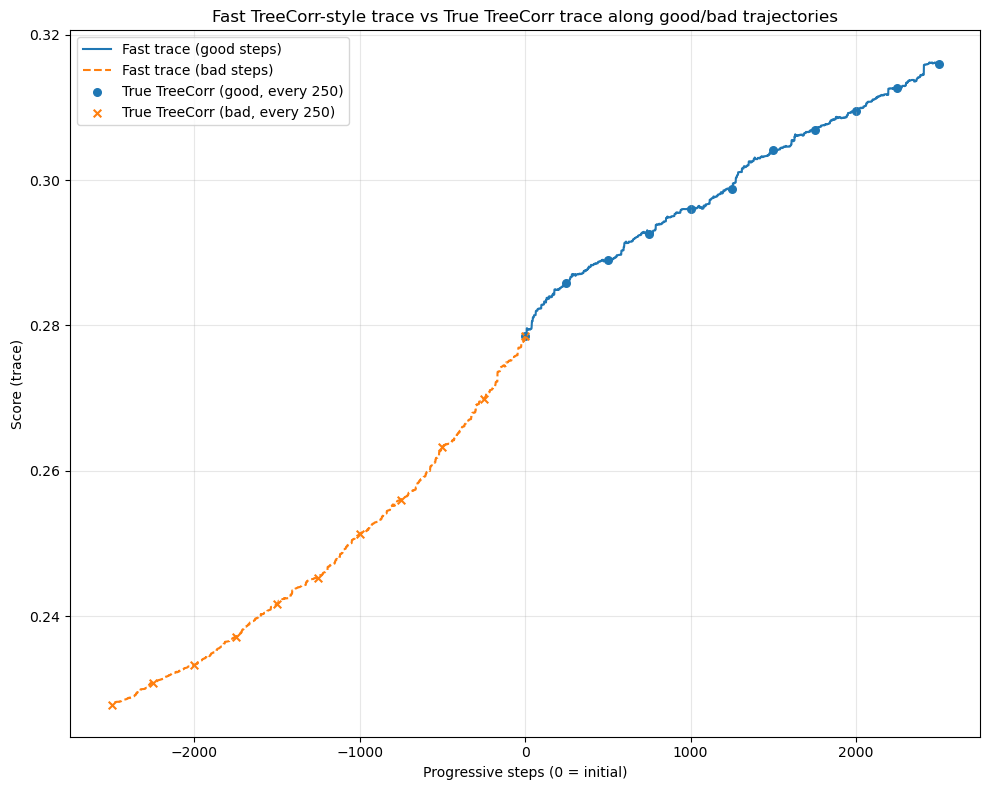

Checkpoint Pearson corr (fast vs true): 1.0000


In [11]:
plt.figure(figsize=(10, 8))

# Fast curves (x=steps, y=score)
plt.plot(y_good, fast_good, label="Fast trace (good steps)")
plt.plot(-y_bad,  fast_bad,  label="Fast trace (bad steps)", linestyle="--")

# True checkpoints
if have_tc:
    yg = np.array(sorted(tc_good.keys()), dtype=np.int32)
    xg = np.array([tc_good[s] for s in yg], dtype=np.float64)
    plt.scatter(yg, xg, s=30, label=f"True TreeCorr (good, every {CHECK_EVERY})")

    yb = np.array(sorted(tc_bad.keys()), dtype=np.int32)
    xb = np.array([tc_bad[s] for s in yb], dtype=np.float64)
    plt.scatter(-yb, xb, s=30, label=f"True TreeCorr (bad, every {CHECK_EVERY})", marker="x")

plt.xlabel("Progressive steps (0 = initial)")
plt.ylabel("Score (trace)")
plt.title("Fast TreeCorr-style trace vs True TreeCorr trace along good/bad trajectories")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# Correlation at checkpoints
if have_tc:
    # combine good+bad checkpoint pairs
    steps_g = np.array(sorted(tc_good.keys()), dtype=np.int32)
    steps_b = np.array(sorted(tc_bad.keys()), dtype=np.int32)

    true_all = np.concatenate([np.array([tc_good[s] for s in steps_g]),
                               np.array([tc_bad[s]  for s in steps_b])])
    fast_all = np.concatenate([fast_good[steps_g],
                               fast_bad[steps_b]])

    # Pearson correlation
    true_mean = true_all.mean()
    fast_mean = fast_all.mean()
    num = np.sum((true_all - true_mean) * (fast_all - fast_mean))
    den = np.sqrt(np.sum((true_all - true_mean) ** 2) * np.sum((fast_all - fast_mean) ** 2))
    pearson = float(num / (den + 1e-12))

    print(f"Checkpoint Pearson corr (fast vs true): {pearson:.4f}")


In [12]:
if have_tc:
    # time a few true computations on current state
    N_TRUE = 3
    t0 = time.perf_counter()
    for _ in range(N_TRUE):
        _ = treecorr_trace_from_columns(som.current_bins, dd_tc, dr_tc, rd_tc, rr_tc, num_bins=K)[0]
    t1 = time.perf_counter()
    print(f"True TreeCorr-from-columns: {N_TRUE} evals in {(t1-t0):.3f}s  | avg {(t1-t0)/N_TRUE:.3f}s")
else:
    print("No TreeCorr pickles found; skipping.")


True TreeCorr-from-columns: 3 evals in 63.887s  | avg 21.296s


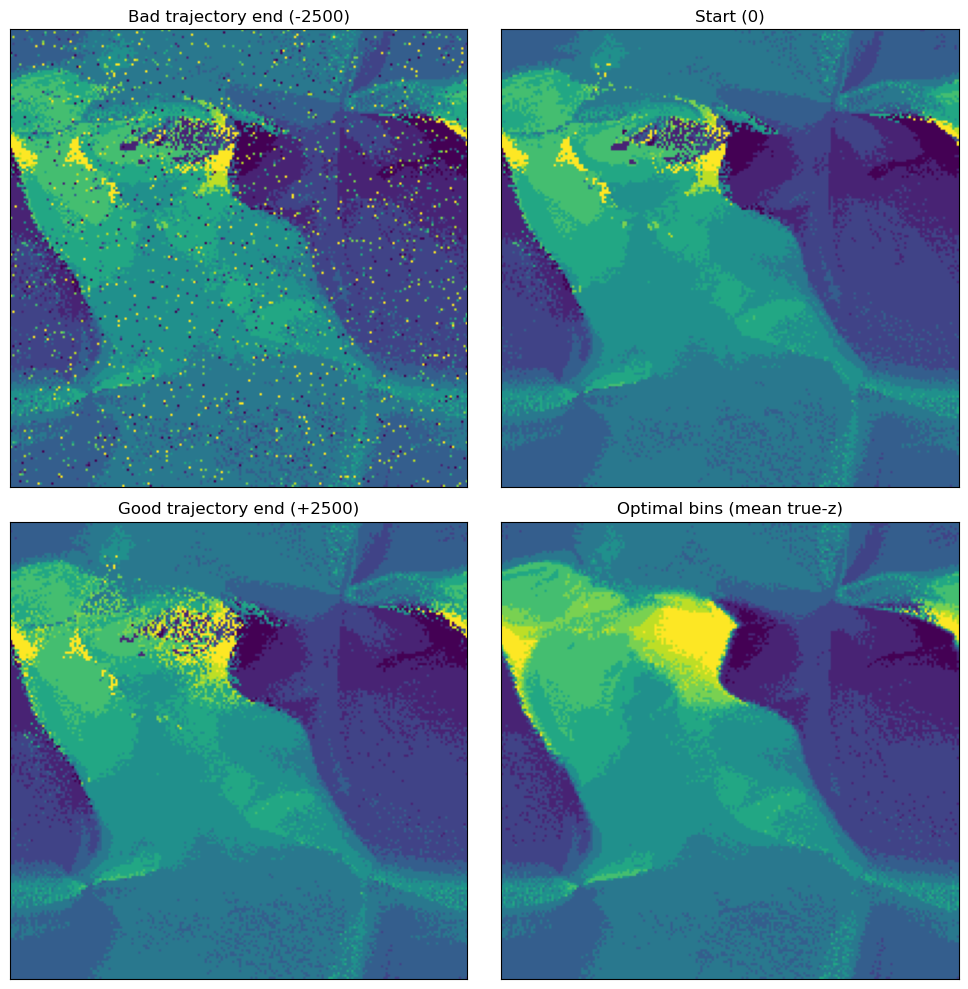

In [13]:
def bins_to_image(bins_1d):
    a = np.asarray(bins_1d, dtype=np.int32).reshape(H, W)
    # flip on x axis
    a = np.flip(a, axis=0)
    return a

# After you run your trajectories, keep the final bin arrays:
# - bins_bad_end
# - bins_start (initial)
# - bins_good_end
# - bins_optimal (optimal_node_bins)

# Example wiring (adapt to your code variables):
bins_start = initial_node_bins.copy()

# already captured from the run:
# bins_bad_end, bins_good_end


bins_optimal = optimal_node_bins.copy()

fig, axs = plt.subplots(2, 2, figsize=(10, 10))

axs[0,0].imshow(bins_to_image(bins_bad_end), vmin=0, vmax=K-1)
axs[0,0].set_title("Bad trajectory end (-2500)")

axs[0,1].imshow(bins_to_image(bins_start), vmin=0, vmax=K-1)
axs[0,1].set_title("Start (0)")

axs[1,0].imshow(bins_to_image(bins_good_end), vmin=0, vmax=K-1)
axs[1,0].set_title("Good trajectory end (+2500)")

axs[1,1].imshow(bins_to_image(bins_optimal), vmin=0, vmax=K-1)
axs[1,1].set_title("Optimal bins (mean true-z)")

for ax in axs.ravel():
    ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.show()


In [14]:
import numpy as np

# bins_start: (N_nodes,)
# bins_optimal: (N_nodes,)
# optional: eligible_nodes (indices of non-empty nodes). If not defined, it will count all nodes.

if "eligible_nodes" in globals():
    idx = eligible_nodes
else:
    idx = np.arange(bins_start.size, dtype=np.int32)

mismatch_mask = (bins_start[idx] != bins_optimal[idx])
n_actions_min = int(np.sum(mismatch_mask))

print(f"Nodes total considered: {idx.size}")
print(f"Nodes needing change (min actions): {n_actions_min}")
print(f"Fraction needing change: {n_actions_min / idx.size:.3%}")


Nodes total considered: 40000
Nodes needing change (min actions): 8206
Fraction needing change: 20.515%


In [15]:
import time
import numpy as np

def greedy_best_bin_for_node(som, node: int, K: int) -> tuple[int, float, bool]:
    """
    Returns:
      best_bin, best_reward, changed
    Greedy w.r.t. current som state and som.reward_trace().
    """
    cur = int(som.current_bins[node])
    base = float(som.reward_trace())

    best_bin = cur
    best_reward = base

    # Try all bins (including current; cheap)
    for b in range(K):
        if b == cur:
            continue
        # apply trial move
        som.force_set_node_bin(node, b)
        r = float(som.reward_trace())

        # revert immediately to keep trials independent
        som.force_set_node_bin(node, cur)

        if r > best_reward:
            best_reward = r
            best_bin = b

    changed = (best_bin != cur)
    return best_bin, best_reward, changed

def benchmark_full_actions(som, n_actions: int, K: int, rng: np.random.Generator, eligible_nodes: np.ndarray):
    som.reset()

    t0 = time.perf_counter()
    n_changed = 0
    rewards = np.empty(n_actions + 1, dtype=np.float64)
    rewards[0] = float(som.reward_trace())

    for a in range(1, n_actions + 1):
        node = int(rng.choice(eligible_nodes))

        best_bin, best_r, changed = greedy_best_bin_for_node(som, node, K)
        if changed:
            som.force_set_node_bin(node, best_bin)
            n_changed += 1

        rewards[a] = float(som.reward_trace())

    dt = time.perf_counter() - t0
    return dt, n_changed, rewards

# --- run benchmark ---
N_ACTIONS = 5000
rng_bench = np.random.default_rng(123)

eligible_nodes = np.flatnonzero(som.node_gal_counts > 0)

dt, n_changed, rewards = benchmark_full_actions(som, N_ACTIONS, K, rng_bench, eligible_nodes)

print(f"Full actions: {N_ACTIONS}")
print(f"Total time: {dt:.3f} s")
print(f"Time per full action: {1e3*dt/N_ACTIONS:.3f} ms")
print(f"Moves that changed bin: {n_changed} ({n_changed/N_ACTIONS:.1%})")
print(f"Reward start/end: {rewards[0]:.6f} -> {rewards[-1]:.6f}")


Full actions: 5000
Total time: 1.735 s
Time per full action: 0.347 ms
Moves that changed bin: 2027 (40.5%)
Reward start/end: 0.278519 -> 0.308711


In [ ]:
import numpy as np
import time

def eval_fast_and_true(
    som,
    bins_state: np.ndarray,
    have_tc: bool,
    dd_tc=None, dr_tc=None, rd_tc=None, rr_tc=None,
    K: int = 11,
):
    """
    Returns (fast_val, true_val_or_nan).
    Assumes:
      - som.set_state(bins_state) or som.set_bins(bins_state) exists; otherwise uses direct assign + rebuild.
      - som.reward_trace() returns fast trace.
      - treecorr_trace_from_columns(...) exists if have_tc.
    """
    # --- set state ---
    if hasattr(som, "set_state"):
        som.set_state(bins_state)
    elif hasattr(som, "set_bins"):
        som.set_bins(bins_state)
    else:
        # fallback: overwrite + rebuild if you have a method
        som.current_bins[:] = np.asarray(bins_state, dtype=np.int32)
        if hasattr(som, "rebuild"):
            som.rebuild()
        elif hasattr(som, "_reset_caches"):
            som._reset_caches()
    # NOTE: Code above DOES NOT WORK due to som class not having the ability to set state directly.
    # So the test below will not work properly... It's defaulted to the best state for the current_bins defined earleir on

    fast_val = float(som.reward_trace())

    if not have_tc:
        return fast_val, np.nan

    true_val, _ = treecorr_trace_from_columns(
        som.current_bins, dd_tc, dr_tc, rd_tc, rr_tc, num_bins=K
    )
    return fast_val, float(true_val)


In [ ]:
import numpy as np

def random_state_test(
    som,
    initial_bins: np.ndarray,
    eligible_nodes: np.ndarray,
    K: int,
    n_states: int = 25,
    flip_frac: float = 0.05,
    rng_seed: int = 0,
    have_tc: bool = False,
    dd_tc=None, dr_tc=None, rd_tc=None, rr_tc=None,
):
    rng = np.random.default_rng(rng_seed)
    N = initial_bins.size

    fast_vals = []
    true_vals = []

    for s in range(n_states):
        bins = initial_bins.copy()

        # flip ~flip_frac of eligible nodes to random bins
        m = max(1, int(flip_frac * eligible_nodes.size))
        flip_nodes = rng.choice(eligible_nodes, size=m, replace=False)

        new_bins = rng.integers(0, K, size=m, dtype=np.int32)
        bins[flip_nodes] = new_bins

        f, t = eval_fast_and_true(
            som, bins, have_tc=have_tc, dd_tc=dd_tc, dr_tc=dr_tc, rd_tc=rd_tc, rr_tc=rr_tc, K=K
        )
        fast_vals.append(f)
        true_vals.append(t)

        print(f"[{s+1:02d}/{n_states}] fast={f:.6f}" + (f" true={t:.6f}" if have_tc else ""))

    fast_vals = np.array(fast_vals, dtype=np.float64)
    true_vals = np.array(true_vals, dtype=np.float64)

    if have_tc:
        # Pearson
        fm = fast_vals.mean()
        tm = true_vals.mean()
        num = np.sum((fast_vals - fm) * (true_vals - tm))
        den = np.sqrt(np.sum((fast_vals - fm)**2) * np.sum((true_vals - tm)**2))
        pearson = float(num / (den + 1e-12))
        print(f"\nRandom-state Pearson corr (fast vs true): {pearson:.6f}")

    return fast_vals, true_vals

# Example call:
fast_rand, true_rand = random_state_test(
    som, initial_node_bins, eligible_nodes, K,
    n_states=25, flip_frac=0.05, rng_seed=1,
    have_tc=have_tc, dd_tc=dd_tc, dr_tc=dr_tc, rd_tc=rd_tc, rr_tc=rr_tc
)

# THIS DOES NOT WORK PROPERLY SEE CELL ABOVE


[01/25] fast=0.308711 true=0.238191
[02/25] fast=0.308711 true=0.238149
[03/25] fast=0.308711 true=0.236321
[04/25] fast=0.308711 true=0.237489
[05/25] fast=0.308711 true=0.239251
[06/25] fast=0.308711 true=0.237344
[07/25] fast=0.308711 true=0.238206
[08/25] fast=0.308711 true=0.239215
[09/25] fast=0.308711 true=0.234903
[10/25] fast=0.308711 true=0.238684
[11/25] fast=0.308711 true=0.235367
[12/25] fast=0.308711 true=0.236948
[13/25] fast=0.308711 true=0.238762
[14/25] fast=0.308711 true=0.236354
[15/25] fast=0.308711 true=0.238699
[16/25] fast=0.308711 true=0.239464
[17/25] fast=0.308711 true=0.238326
[18/25] fast=0.308711 true=0.236388
[19/25] fast=0.308711 true=0.234640
[20/25] fast=0.308711 true=0.236891
[21/25] fast=0.308711 true=0.239223
[22/25] fast=0.308711 true=0.235990
[23/25] fast=0.308711 true=0.238530
[24/25] fast=0.308711 true=0.237587
[25/25] fast=0.308711 true=0.238715

Random-state Pearson corr (fast vs true): 0.000000


In [18]:
def local_delta_test(
    som,
    base_bins: np.ndarray,
    eligible_nodes: np.ndarray,
    K: int,
    n_trials: int = 50,
    rng_seed: int = 0,
    have_tc: bool = False,
    dd_tc=None, dr_tc=None, rd_tc=None, rr_tc=None,
):
    rng = np.random.default_rng(rng_seed)

    # set baseline
    if hasattr(som, "set_state"):
        som.set_state(base_bins)
    else:
        som.current_bins[:] = np.asarray(base_bins, dtype=np.int32)
        if hasattr(som, "_reset_caches"):
            som._reset_caches()

    base_fast = float(som.reward_trace())
    if have_tc:
        base_true, _ = treecorr_trace_from_columns(som.current_bins, dd_tc, dr_tc, rd_tc, rr_tc, num_bins=K)
        base_true = float(base_true)
    else:
        base_true = np.nan

    dfast = []
    dtrue = []

    for i in range(n_trials):
        node = int(rng.choice(eligible_nodes))
        cur = int(som.current_bins[node])

        # pick a different bin
        cand = int(rng.integers(0, K))
        while cand == cur:
            cand = int(rng.integers(0, K))

        # apply
        som.force_set_node_bin(node, cand)
        f1 = float(som.reward_trace())
        if have_tc:
            t1, _ = treecorr_trace_from_columns(som.current_bins, dd_tc, dr_tc, rd_tc, rr_tc, num_bins=K)
            t1 = float(t1)

        # revert
        som.force_set_node_bin(node, cur)

        dfast.append(f1 - base_fast)
        if have_tc:
            dtrue.append(t1 - base_true)

        print(f"[{i+1:02d}/{n_trials}] node={node} {cur}->{cand} Δfast={dfast[-1]:+.6e}" + (f" Δtrue={dtrue[-1]:+.6e}" if have_tc else ""))

    dfast = np.array(dfast, dtype=np.float64)
    dtrue = np.array(dtrue, dtype=np.float64) if have_tc else None

    if have_tc:
        # Pearson on deltas
        fm = dfast.mean()
        tm = dtrue.mean()
        num = np.sum((dfast - fm) * (dtrue - tm))
        den = np.sqrt(np.sum((dfast - fm)**2) * np.sum((dtrue - tm)**2))
        pearson = float(num / (den + 1e-12))
        print(f"\nLocal-Δ Pearson corr (Δfast vs Δtrue): {pearson:.6f}")

    return dfast, dtrue

# Example call:
dfast, dtrue = local_delta_test(
    som, initial_node_bins, eligible_nodes, K,
    n_trials=50, rng_seed=2,
    have_tc=have_tc, dd_tc=dd_tc, dr_tc=dr_tc, rd_tc=rd_tc, rr_tc=rr_tc
)


[01/50] node=33503 3->2 Δfast=-5.939816e-07 Δtrue=-5.888519e-07
[02/50] node=4372 3->4 Δfast=-5.899568e-06 Δtrue=-5.928609e-06
[03/50] node=32569 6->4 Δfast=+1.020169e-06 Δtrue=+8.787064e-07
[04/50] node=3676 4->3 Δfast=-4.297388e-06 Δtrue=-4.182603e-06
[05/50] node=24004 1->8 Δfast=-1.926698e-04 Δtrue=-2.106226e-04
[06/50] node=29142 2->10 Δfast=-1.460943e-04 Δtrue=-1.564583e-04
[07/50] node=7516 4->9 Δfast=-1.342020e-04 Δtrue=-1.516501e-04
[08/50] node=2205 3->6 Δfast=-4.107604e-06 Δtrue=-3.852416e-06
[09/50] node=10998 2->7 Δfast=-4.863046e-06 Δtrue=-4.570880e-06
[10/50] node=12228 2->6 Δfast=-1.743641e-06 Δtrue=-1.589665e-06
[11/50] node=10406 2->1 Δfast=-6.630824e-06 Δtrue=-6.365682e-06
[12/50] node=29967 1->4 Δfast=+2.918946e-06 Δtrue=+2.301170e-06
[13/50] node=27148 1->7 Δfast=-2.424346e-05 Δtrue=-2.342932e-05
[14/50] node=37809 3->4 Δfast=-1.065366e-05 Δtrue=-1.090361e-05
[15/50] node=8789 4->6 Δfast=-2.944684e-06 Δtrue=-2.784330e-06
[16/50] node=37398 3->10 Δfast=-3.069297e-05

In [19]:
def timing_comparison(
    som,
    states: list[np.ndarray],
    have_tc: bool,
    dd_tc=None, dr_tc=None, rd_tc=None, rr_tc=None,
    K: int = 11,
):
    fast_times = []
    true_times = []
    fast_vals = []
    true_vals = []

    for i, bins in enumerate(states):
        # set state
        if hasattr(som, "set_state"):
            som.set_state(bins)
        else:
            som.current_bins[:] = np.asarray(bins, dtype=np.int32)
            if hasattr(som, "_reset_caches"):
                som._reset_caches()

        t0 = time.perf_counter()
        fv = float(som.reward_trace())
        fast_times.append(time.perf_counter() - t0)
        fast_vals.append(fv)

        if have_tc:
            t0 = time.perf_counter()
            tv, _ = treecorr_trace_from_columns(som.current_bins, dd_tc, dr_tc, rd_tc, rr_tc, num_bins=K)
            true_times.append(time.perf_counter() - t0)
            true_vals.append(float(tv))

        print(f"[{i+1:02d}/{len(states)}] fast={fast_times[-1]:.6f}s" + (f" true={true_times[-1]:.3f}s" if have_tc else ""))

    print("\nFast: mean {:.6f}s | median {:.6f}s".format(float(np.mean(fast_times)), float(np.median(fast_times))))
    if have_tc:
        print("True: mean {:.3f}s | median {:.3f}s".format(float(np.mean(true_times)), float(np.median(true_times))))

    return (np.array(fast_vals), np.array(true_vals) if have_tc else None,
            np.array(fast_times), np.array(true_times) if have_tc else None)

# Build a small suite of states: start + a few random perturbations
states = [initial_node_bins.copy(), ...]
timing_comparison(som, states, have_tc, dd_tc, dr_tc, rd_tc, rr_tc, K=K)


[01/2] fast=0.000348s true=21.859s


TypeError: int() argument must be a string, a bytes-like object or a real number, not 'ellipsis'